**Space and Time**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Set the font family and size for matplot figures
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 10

In [3]:
# set Parameters
nx = 41 # number of spacial discrete points
L = 2.0 # length of the 1D Domian
dx = L/ (nx-1) # spacial grid size
nt = 25 # number of time steps
dt = 0.02 # time-step size
c = 1.0 # convectioon speed

# define the grid point coordinates, generates an array of evenly spaced numbers over a specified interval.
x = np.linspace(0.0,L,num=nx)

In [4]:
# Set initial conditions with 1.0 everywhere (for now).
u0 = np.ones(nx)
# Get a list of indices where 0.5 <= x <= 1.0.
mask = np.where(np.logical_and(x >= 0.5, x <= 1.0))
print(mask)

(array([10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]),)


^Grabs values from x array (which counts to 2 by 0.05) and returns the index of the values between 0.5 and 1

In [5]:
# Set initial condition u = 2.0 where 0.5 <= x <= 1.0.
u0[mask] = 2.0
print(u0)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


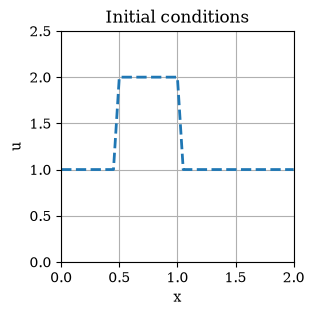

In [6]:
# Plot the initial conditions.
plt.figure(figsize=(3.0, 3.0))
plt.title('Initial conditions')
plt.xlabel('x')
plt.ylabel('u')
plt.grid()
plt.plot(x, u0, color='tab:blue', linestyle='--', linewidth=2)
plt.xlim(0.0, L)
plt.ylim(0.0, 2.5);

^It does look pretty close to what we expected. But it looks like the sides of the square wave are not perfectly vertical. Is that right? Think for a bit.

now we apply our formula: ### The Upwind Finite-Difference Formula
```python
u[i] = un[i] - c * (dt / dx) * (un[i] - un[i - 1])

In [7]:
u = u0.copy()
for n in range(nt):
    un = u.copy()
    for i in range(1, nx):
        u[i] = un[i] - c * dt / dx * (un[i] - un[i - 1])

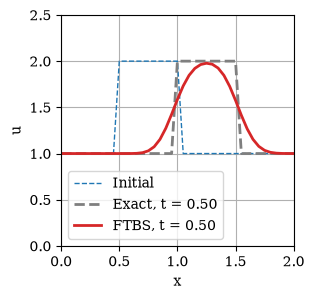

In [8]:
# Evaluate the exact translated square wave at the final time.
t_final = nt * dt
u_exact = np.ones_like(x)
exact_mask = np.where(
    np.logical_and(x >= 0.5 + c * t_final,
                   x <= 1.0 + c * t_final)
)
u_exact[exact_mask] = 2.0

# Plot the numerical and exact solutions with the initial condition.
plt.figure(figsize=(3.0, 3.0))
plt.xlabel('x')
plt.ylabel('u')
plt.grid()
plt.plot(x, u0, label='Initial',
            color='tab:blue', linestyle='--', linewidth=1)
plt.plot(x, u_exact, label=f'Exact, t = {t_final:.2f}',
            color='tab:gray', linestyle='--', linewidth=2)
plt.plot(x, u, label=f'FTBS, t = {t_final:.2f}',
            color='tab:red', linestyle='-', linewidth=2)
plt.legend()
plt.xlim(0.0, L)
plt.ylim(0.0, 2.5);

**My Prediction that a finer spatial grid might improve the solution (inc. nx)**

The stability of the Forward-Time, Backward-Space (FTBS) upwind scheme depends on the Courant-Friedrichs-Lewy (CFL) condition:

$$\nu = \frac{c \Delta t}{\Delta x} \le 1$$

* **Reducing Grid Size ($\Delta x$):** I**ncreasing the number of spatial points $nx$ decreases the spatial grid step size**:
  $$\Delta x = \frac{L}{nx - 1}$$

* **CFL Growth:** Since wave speed $c$ and time step $\Delta t$ remain fixed, decreasing $\Delta x$ directly increases the CFL number $\nu$.

* **Instability Mechanism:** Once $\Delta x$ becomes small enough that $\nu > 1$, the physical domain of **dependence expands beyond the numerical stencil**. The FTBS amplification factor magnitude $|\xi|$ exceeds $1$, causing the scheme to become unconditionally unstable.

nx =  41: min(u) =    1.000, max(u) =    1.977
nx =  81: min(u) =    1.000, max(u) =    2.000
nx = 101: min(u) =    1.000, max(u) =    2.000
nx = 121: min(u) = -521.913, max(u) =  524.913


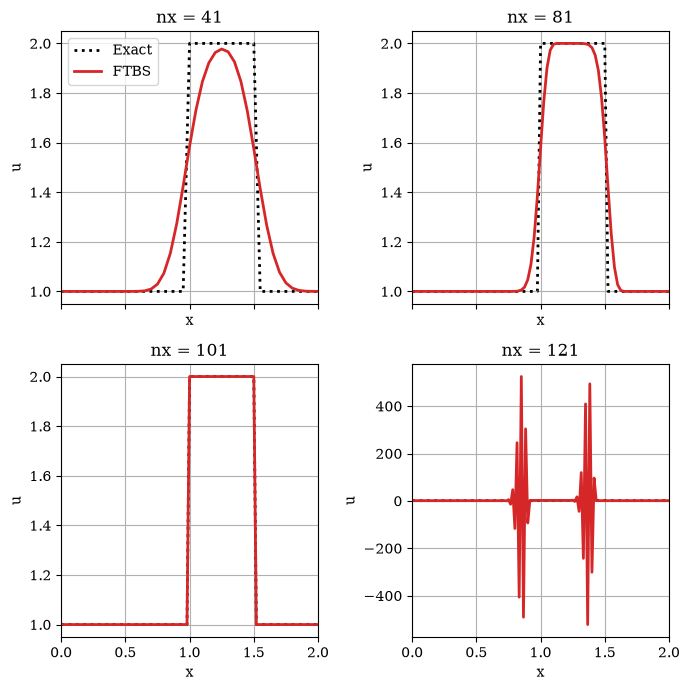

In [9]:
# Change only the number of spatial points.
nx_trials = [41, 81, 101, 121]
fig, axes = plt.subplots(2, 2, figsize=(7.0, 7.0), sharex=True)

for ax, nx_trial in zip(axes.flat, nx_trials):
    dx_trial = L / (nx_trial - 1)
    x_trial = np.linspace(0.0, L, num=nx_trial)
    u_trial = np.ones(nx_trial)
    pulse = np.where(
        np.logical_and(x_trial >= 0.5, x_trial <= 1.0)
    )
    u_trial[pulse] = 2.0

    for n in range(nt):
        un_trial = u_trial.copy()
        for i in range(1, nx_trial):
            u_trial[i] = (
                un_trial[i]
                - c * dt / dx_trial
                * (un_trial[i] - un_trial[i - 1])
            )

    exact_trial = np.ones(nx_trial)
    exact_pulse = np.where(
        np.logical_and(
            x_trial >= 0.5 + c * t_final,
            x_trial <= 1.0 + c * t_final,
        )
    )
    exact_trial[exact_pulse] = 2.0

    ax.plot(x_trial, exact_trial, color='black',
            linestyle=':', linewidth=2, label='Exact')
    ax.plot(x_trial, u_trial, color='tab:red',
            linewidth=2, label='FTBS')
    ax.set_title(f'nx = {nx_trial}')
    ax.set_xlabel('x')
    ax.set_ylabel('u')
    ax.set_xlim(0.0, L)
    ax.grid()
    print(f'nx = {nx_trial:3d}: '          f'min(u) = {u_trial.min():8.3f}, '          f'max(u) = {u_trial.max():8.3f}')

axes.flat[0].legend()
fig.tight_layout();

**Thus nx = 81 and 101 are ideally stable**

## Spatial Truncation Error

**Prediction**
Halving the spatial step size cuts the numerical truncation error in half ($50\%$ reduction).

$$E_{\text{old}} = C \cdot \Delta x$$

$$E_{\text{new}} = C \cdot \left(\frac{\Delta x}{2}\right) = \frac{1}{2} \left(C \cdot \Delta x\right) = \frac{1}{2} E_{\text{old}}$$


## A controlled spatial refinement study

The square wave makes numerical diffusion easy to see, but its jumps **do not satisfy the smoothness assumed in the Taylor expansion above**. To measure the formal spatial behavior of the scheme, use a smooth **Gaussian pulse on the same unit background**. Its exact solution is the same profile translated by ct.

In [10]:
def gaussian_profile(x, center=0.7, width=0.2):
    '''Return a smooth pulse on a unit background.'''
    return 1.0 + np.exp(-((x - center) / width)**2)


def advance_linear_convection(u0, c, dx, dt, num_steps):
    '''Advance linear convection with the FTBS scheme.'''
    u = u0.copy()
    for n in range(num_steps):
        un = u.copy()
        for i in range(1, u.size):
            u[i] = un[i] - c * dt / dx * (un[i] - un[i - 1])
    return u

 nx       dx      E(dt)     E(dt/2)   order
 41   0.05000  3.819e-02  3.823e-02    ---
 81   0.02500  2.011e-02  2.015e-02   0.93
161   0.01250  1.031e-02  1.035e-02   0.96
321   0.00625  5.196e-03  5.237e-03   0.99


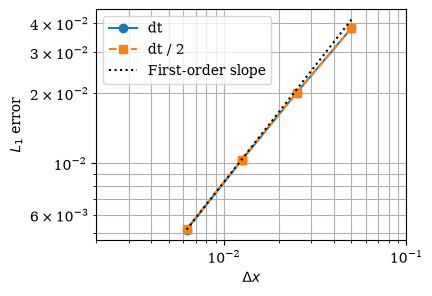

In [12]:
# Compare several spatial grids at one physical time.
nx_values = np.array([41, 81, 161, 321])
dt_values = [1.0e-4, 5.0e-5] # time step size
t_study = 0.1
center = 0.7
width = 0.2
dx_values = L / (nx_values - 1) #  spatial grid size
error_results = []

for dt_trial in dt_values:
    num_steps = int(round(t_study / dt_trial))
    errors = []
    for nx_trial, dx_trial in zip(nx_values, dx_values):
        x_trial = np.linspace(0.0, L, num=nx_trial)
        u0_trial = gaussian_profile(x_trial, center, width)
        u_trial = advance_linear_convection(
            u0_trial, c, dx_trial, dt_trial, num_steps
        )
        u_exact_trial = gaussian_profile(
            x_trial, center + c * t_study, width
        )
        error = dx_trial * np.sum(np.abs(u_trial - u_exact_trial))
        errors.append(error)
    error_results.append(errors)

error_results = np.array(error_results)
orders = np.log(
    error_results[0, :-1] / error_results[0, 1:]
) / np.log(dx_values[:-1] / dx_values[1:])

print(' nx       dx      E(dt)     E(dt/2)   order')
for j, (nx_trial, dx_trial) in enumerate(zip(nx_values, dx_values)):
    order_text = '  ---' if j == 0 else f'{orders[j - 1]:5.2f}'
    print(f'{nx_trial:3d}  {dx_trial:8.5f}  '          f'{error_results[0, j]:9.3e}  '          f'{error_results[1, j]:9.3e}  {order_text}')

# Compare the errors with a first-order reference slope.
first_order = (
    error_results[0, -1] * dx_values / dx_values[-1]
)
plt.figure(figsize=(4.0, 3.0))
plt.loglog(dx_values, error_results[0], 'o-', label='dt')
plt.loglog(dx_values, error_results[1], 's--', label='dt / 2')
plt.loglog(dx_values, first_order, ':', color='black',
           label='First-order slope')
plt.xlabel(r'$\Delta x$')
plt.ylabel(r'$L_1$ error')
plt.grid(which='both')
plt.xlim([2e-3, 1e-1])
plt.legend();

**What I see:**

the error cuts roughly in half at each step (e.g., $3.819 \times 10^{-2} \to 2.011 \times 10^{-2} \to 1.031 \times 10^{-2} \to 5.196 \times 10^{-3}$).

the backward spatial difference is approx first-order accurate in space

Comparing $E(dt)$ ($dt = 1.0 \times 10^{-4}$) to $E(dt/2)$ ($dt = 5.0 \times 10^{-5}$) shows virtually identical error values across both columns. This confirms that for these tiny time-step choices, the spatial discretization error ($\Delta x$) completely dominates over temporal error ($\Delta t$).

**The plot**

On a $\log(L_1 \text{ Error})$ vs $\log(\Delta x)$ plot, the simulated error curves (dt and dt/2) sit directly on top of each other and run parallel to the black dotted First-order reference line (a slope of 1).

## Non-linear convection

The only difference with the linear case is that we’ve replaced the constant wave speed c by the variable speed u. The equation is non-linear because now we have a product of the solution and one of its derivatives: the product u ∂u/∂x

In [13]:
# Set parameters.
nx = 41  # number of spatial discrete points
L = 2.0  # length of the 1D domain
dx = L / (nx - 1)  # spatial grid size
nt = 10  # number of time steps
dt = 0.02  # time-step size

x = np.linspace(0.0, L, num=nx)
u0 = np.ones(nx)
mask = np.where(np.logical_and(x >= 0.5, x <= 1.0))
u0[mask] = 2.0

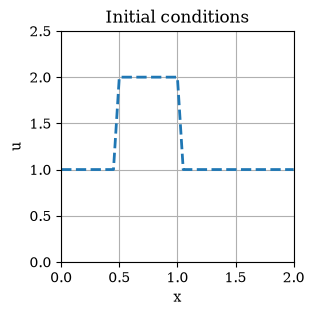

In [14]:
# Plot the initial conditions.
plt.figure(figsize=(3.0, 3.0))
plt.title('Initial conditions')
plt.xlabel('x')
plt.ylabel('u')
plt.grid()
plt.plot(x, u0, color='C0', linestyle='--', linewidth=2)
plt.xlim(0.0, L)
plt.ylim(0.0, 2.5);

In [15]:
for n in range(nt):  
  un = u.copy() 
  for i in range(1, nx): 
    u[i] = un[i] - un[i]*dt/dx*(un[i]-un[i-1]) 

Vectorized Operation: Check notes

You read strictly from un (the old snapshot) while writing results into u (the new snapshot). Nothing in un changes during the loop.


Correct Update (Using Copy / Vectorized Slices)Node 1 ($i = 1$):$$u_1^{n+1} = 2.0 - 0.5 \cdot 2.0 \cdot (2.0 - 1.0) = \mathbf{1.0}$$Node 2 ($i = 2$):Reads **true historical** $u_1^n = \mathbf{2.0}$:$$u_2^{n+1} = 1.5 - 0.5 \cdot 1.5 \cdot (1.5 - \mathbf{2.0}) = 1.5 - 0.5 \cdot 1.5 \cdot (-0.5) = 1.5 + 0.375 = \mathbf{1.875}$$

In [16]:
# Compute the solution using Euler's method and array slicing.
u = u0.copy()
for n in range(nt):
    u[1:] = u[1:] - dt / dx * u[1:] * (u[1:] - u[:-1])

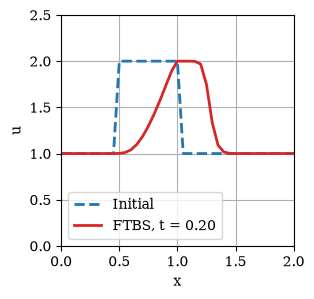

In [17]:
# Plot the solution after nt time steps with the initial condition.
t_final = nt * dt
plt.figure(figsize=(3.0, 3.0))
plt.xlabel('x')
plt.ylabel('u')
plt.grid()
plt.plot(x, u0, label='Initial',
            color='tab:blue', linestyle='--', linewidth=2)
plt.plot(x, u, label=f'FTBS, t = {t_final:.2f}',
            color='tab:red', linestyle='-', linewidth=2)
plt.legend()
plt.xlim(0.0, L)
plt.ylim(0.0, 2.5);

we see that we have **lost the sharp sides of our initial square wave,** but there’s more. Now, **the wave has also lost symmetry!** The front of the wave steepens because larger values of u move faster than smaller values. 

## Implement Both Updates

In [18]:
def nonlinear_flux(u):
    '''Return the quadratic flux for nonlinear convection.'''
    return 0.5 * u**2


def pointwise_step(u, dt, dx):
    '''Advance one step using the pointwise form.'''
    u_next = u.copy()
    u_next[1:] = (
        u[1:]
        - dt / dx * u[1:] * (u[1:] - u[:-1])
    )
    return u_next


def conservative_step(u, dt, dx):
    '''Advance one step using differences of the quadratic flux.'''
    u_next = u.copy()
    u_next[1:] = (
        u[1:]
        - dt / dx
        * (nonlinear_flux(u[1:]) - nonlinear_flux(u[:-1]))
    )
    return u_next

In [19]:
u_test = np.array([1.0, 2.0, 1.0])
pointwise_expected = np.array([1.0, 1.8, 1.1])
conservative_expected = np.array([1.0, 1.85, 1.15])

np.testing.assert_allclose(
    pointwise_step(u_test, dt=0.1, dx=1.0),
    pointwise_expected,
)
np.testing.assert_allclose(
    conservative_step(u_test, dt=0.1, dx=1.0),
    conservative_expected,
)
np.testing.assert_allclose(u_test, [1.0, 2.0, 1.0])

constant_test = np.full(5, 1.5)
np.testing.assert_allclose(
    pointwise_step(constant_test, dt=0.1, dx=1.0),
    constant_test,
)
np.testing.assert_allclose(
    conservative_step(constant_test, dt=0.1, dx=1.0),
    constant_test,
)

Agent algorithm-comparison task brief
- Goal and scope: Add a comparison driver that compares my existing `pointwise_step()` and `conservative_step()` functions. Do not implement, rewrite, or repair either method. Prefer named functions and straightforward, readable loops. The comparison concerns discrete behavior only; deriving shock speeds, introducing another scheme, and making the final numerical judgment are out of scope.
- Problem data: Use $x \in [0, 2]$, `nx_values = [81, 161, 321, 641, 1281]`, and $t_{\text{compare}} = 0.15$. For each grid, start with a target $\Delta t = 0.2 \cdot \Delta x$, round the step count to reach the common final time, and then reset $\Delta t = t_{\text{compare}} / \text{num\_steps}$ so every run ends at exactly the same time. Compare (a) the smooth hump $1 + \exp\left[-\left(\frac{x - 0.7}{0.2}\right)^2\right]$ and (b) the square pulse with background $1$ and value $2$ on $0.5 \le x \le 1$. Each run must begin from a fresh copy of the same initial array.
- Required diagnostics: First report the maximum one-step change produced by each method from a constant array with value $1.5$. Write a reusable runner named `run_balance_comparison(step_function, flux_function, initial_state, dt, dx, num_steps)`. It must return a dictionary containing `u_final`, `initial_total`, `final_total`, `total_change`, and `balance_residual`.
- For every run, calculate these three diagnostics:
  $$M(u) = \Delta x \sum_i u_i$$
  $$R = M_{\text{final}} - M_{\text{initial}} + \sum_n \Delta t \left[ f(u_N^n) - f(u_0^n) \right]$$
  $$D = \Delta x \sum_i \left\vert{} u_i^{\text{pointwise}} - u_i^{\text{conservative}} \right\vert{}$$
  Here, $M$ is the discrete total, $R$ is the cumulative balance residual, and $D$ is the inter-algorithm difference at the final time. Evaluate $M$ for the initial and final states. In $R$, use the boundary values from the state before each update. Evaluate $D$ using the two final solutions on the same grid.
- Required output: Produce one readable table for each profile with `nx`, `dx`, adjusted $\Delta t$, step count, $D$, both balance residuals, and both initial-to-final total changes. Produce a figure showing both final solutions on the finest grid for each profile and a log-log plot of $D$ against $\Delta x$. Label methods, profiles, axes, and final time. Expose numerical values; do not replace them with pass/fail messages or a conclusion. Use only the NumPy and Matplotlib imports already present.
- Permissions and stopping rule: Inspect this notebook and add exactly three Python cells followed by one Markdown cell that records the added functions, experiment, plots, and any assumptions. Do not execute any cell, alter existing cells, write another file, install anything, or use the network. Stop after inserting those four cells and report that the comparison driver is ready for human audit.
- Done when: The unexecuted cells contain the constant-state comparison, reusable balance runner, two-profile grid study, required tables and plots, plus the change record. An expected trend is not a completion condition; preserve and expose surprising results.

In [20]:
# Comparison helpers and the first diagnostic: constant-state one-step changes.
def run_balance_comparison(
    step_function, flux_function, initial_state, dt, dx, num_steps
):
    """Advance a fresh state and accumulate the discrete boundary balance."""
    state = initial_state.copy()
    initial_total = dx * np.sum(state)
    boundary_flux_sum = 0.0
    for step_index in range(num_steps):
        # Boundary fluxes must come from the state BEFORE this update.
        boundary_flux_sum += dt * (
            flux_function(state[-1]) - flux_function(state[0])
        )
        state = step_function(state, dt, dx)
    final_total = dx * np.sum(state)
    total_change = final_total - initial_total
    return {
        'u_final': state,
        'initial_total': initial_total,
        'final_total': final_total,
        'total_change': total_change,
        'balance_residual': total_change + boundary_flux_sum,
    }


def comparison_smooth_hump(grid):
    """Return the specified smooth hump on a unit background."""
    return 1.0 + np.exp(-((grid - 0.7) / 0.2)**2)


def comparison_square_pulse(grid):
    """Return the specified square pulse, including both endpoints."""
    initial_state = np.ones_like(grid)
    initial_state[(grid >= 0.5) & (grid <= 1.0)] = 2.0
    return initial_state


def report_constant_state_comparison():
    """Print actual maximum absolute one-step changes for both methods."""
    constant_state = np.full(81, 1.5)
    constant_dx = 2.0 / (constant_state.size - 1)
    constant_dt = 0.2 * constant_dx
    print('Constant state u = 1.5: maximum absolute one-step change')
    print(f'nx = {constant_state.size}, dx = {constant_dx:.8e}, '
          f'dt = {constant_dt:.8e}')
    for method_name, step_function in [
        ('Pointwise', pointwise_step),
        ('Conservative', conservative_step),
    ]:
        next_state = step_function(
            constant_state.copy(), constant_dt, constant_dx
        )
        max_change = np.max(np.abs(next_state - constant_state))
        print(f'{method_name:12s}: {max_change:.16e}')


report_constant_state_comparison()


Constant state u = 1.5: maximum absolute one-step change
nx = 81, dx = 2.50000000e-02, dt = 5.00000000e-03
Pointwise   : 0.0000000000000000e+00
Conservative: 0.0000000000000000e+00


**Mass conservation**

In [21]:
# Two-profile grid study, using the existing methods and nonlinear_flux.
def build_balance_comparison_study():
    """Return per-grid diagnostics and final states for both profiles."""
    nx_values = [81, 161, 321, 641, 1281]
    t_compare = 0.15
    study = {}
    for profile_name, profile_function in [
        ('Smooth hump', comparison_smooth_hump),
        ('Square pulse', comparison_square_pulse),
    ]:
        rows = []
        for nx_trial in nx_values:
            grid = np.linspace(0.0, 2.0, nx_trial)
            dx_trial = 2.0 / (nx_trial - 1)
            target_dt = 0.2 * dx_trial
            num_steps = int(round(t_compare / target_dt))
            dt_trial = t_compare / num_steps
            initial_state = profile_function(grid)
            pointwise_result = run_balance_comparison(
                pointwise_step, nonlinear_flux, initial_state,
                dt_trial, dx_trial, num_steps
            )
            conservative_result = run_balance_comparison(
                conservative_step, nonlinear_flux, initial_state,
                dt_trial, dx_trial, num_steps
            )
            difference = dx_trial * np.sum(np.abs(
                pointwise_result['u_final']
                - conservative_result['u_final']
            ))
            rows.append({
                'nx': nx_trial, 'dx': dx_trial, 'dt': dt_trial,
                'num_steps': num_steps, 'D': difference, 'x': grid,
                'pointwise': pointwise_result,
                'conservative': conservative_result,
            })
        study[profile_name] = rows
    return t_compare, study


def print_balance_comparison_tables(study, final_time):
    """Print one numerical table per profile; P/C identify the methods."""
    for profile_name, rows in study.items():
        print(f'\n{profile_name}, t = {final_time:.2f}')
        print('P = Pointwise; C = Conservative; '
              'change = final total - initial total')
        print(f"{'nx':>5} {'dx':>13} {'adjusted dt':>13} {'steps':>6} "
              f"{'D':>13} {'R(P)':>14} {'R(C)':>14} "
              f"{'change(P)':>14} {'change(C)':>14}")
        for row in rows:
            pointwise = row['pointwise']
            conservative = row['conservative']
            print(
                f"{row['nx']:5d} {row['dx']:13.6e} "
                f"{row['dt']:13.6e} {row['num_steps']:6d} "
                f"{row['D']:13.6e} "
                f"{pointwise['balance_residual']:14.6e} "
                f"{conservative['balance_residual']:14.6e} "
                f"{pointwise['total_change']:14.6e} "
                f"{conservative['total_change']:14.6e}"
            )


comparison_final_time, balance_comparison_results = (
    build_balance_comparison_study()
)
print_balance_comparison_tables(
    balance_comparison_results, comparison_final_time
)



Smooth hump, t = 0.15
P = Pointwise; C = Conservative; change = final total - initial total
   nx            dx   adjusted dt  steps             D           R(P)           R(C)      change(P)      change(C)
   81  2.500000e-02  5.000000e-03     30  1.069757e-02  -1.069757e-02  -2.109440e-17  -1.069686e-02   7.177693e-07
  161  1.250000e-02  2.500000e-03     60  5.864584e-03  -5.864584e-03   4.574119e-16  -5.863867e-03   7.177693e-07
  321  6.250000e-03  1.250000e-03    120  3.097979e-03  -3.097979e-03   6.658562e-16  -3.097261e-03   7.177693e-07
  641  3.125000e-03  6.250000e-04    240  1.598138e-03  -1.598138e-03   1.886686e-15  -1.597420e-03   7.177693e-07
 1281  1.562500e-03  3.125000e-04    480  8.127667e-04  -8.127667e-04   4.247159e-15  -8.120489e-04   7.177693e-07

Square pulse, t = 0.15
P = Pointwise; C = Conservative; change = final total - initial total
   nx            dx   adjusted dt  steps             D           R(P)           R(C)      change(P)      change(C)
   81  2

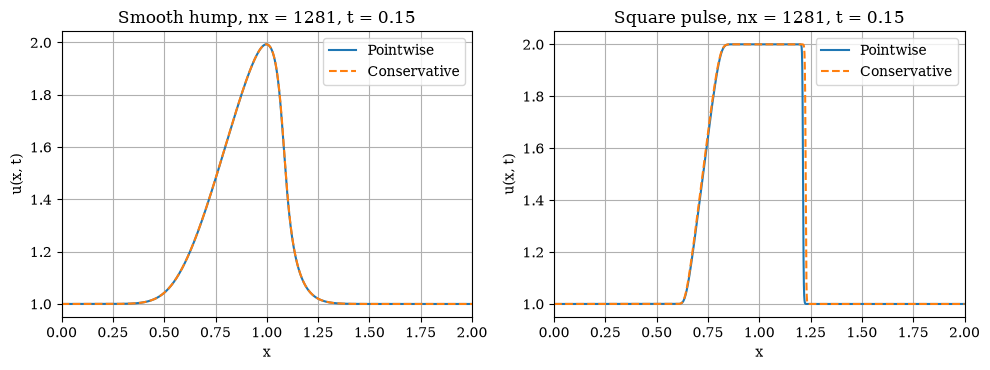

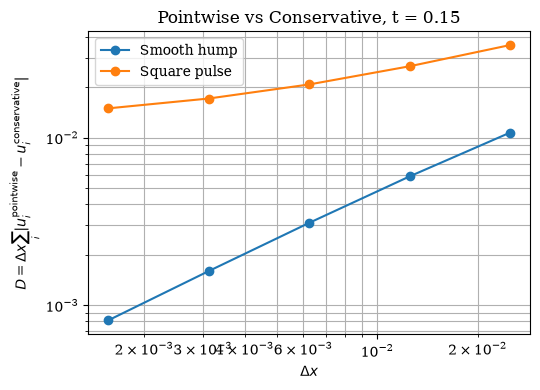

In [22]:
# Finest-grid solutions and inter-algorithm differences under refinement.
def plot_balance_comparison(study, final_time):
    """Plot both methods for each profile and D versus spatial spacing."""
    solution_figure, solution_axes = plt.subplots(
        1, 2, figsize=(10.0, 3.8)
    )
    for axis, (profile_name, rows) in zip(solution_axes, study.items()):
        finest = rows[-1]
        axis.plot(
            finest['x'], finest['pointwise']['u_final'],
            label='Pointwise', color='tab:blue', linestyle='-'
        )
        axis.plot(
            finest['x'], finest['conservative']['u_final'],
            label='Conservative', color='tab:orange', linestyle='--'
        )
        axis.set_title(
            f"{profile_name}, nx = {finest['nx']}, t = {final_time:.2f}"
        )
        axis.set_xlabel('x')
        axis.set_ylabel('u(x, t)')
        axis.set_xlim(0.0, 2.0)
        axis.grid()
        axis.legend()
    solution_figure.tight_layout()

    difference_figure, difference_axis = plt.subplots(figsize=(5.5, 4.0))
    for profile_name, rows in study.items():
        spacings = [row['dx'] for row in rows]
        differences = [row['D'] for row in rows]
        difference_axis.loglog(
            spacings, differences, 'o-', label=profile_name
        )
    difference_axis.set_title(
        f'Pointwise vs Conservative, t = {final_time:.2f}'
    )
    difference_axis.set_xlabel(r'$\Delta x$')
    difference_axis.set_ylabel(
        r'$D = \Delta x\sum_i |u_i^{\mathrm{pointwise}}'
        r' - u_i^{\mathrm{conservative}}|$'
    )
    difference_axis.grid(which='both')
    difference_axis.legend()
    difference_figure.tight_layout()
    plt.show()


plot_balance_comparison(
    balance_comparison_results, comparison_final_time
)


### Algorithm-comparison change record

Added exactly three Python cells immediately below the task brief, followed by this Markdown record. Existing cells, methods, and outputs are unchanged. These additions have not been executed and are ready for human audit.

- **Functions:** `run_balance_comparison(step_function, flux_function, initial_state, dt, dx, num_steps)` copies the initial state, evaluates initial and final totals using all grid points, accumulates boundary flux differences before each update, and returns `u_final`, `initial_total`, `final_total`, `total_change`, and `balance_residual`. Added named profile helpers, `report_constant_state_comparison`, `build_balance_comparison_study`, `print_balance_comparison_tables`, and `plot_balance_comparison`.
- **Experiment:** The first output reports maximum absolute one-step changes from a constant array of 1.5 for both existing methods, using 81 points, `dx = 2/80`, and `dt = 0.2*dx`. The study uses the specified smooth hump and inclusive square pulse on [0, 2], grids [81, 161, 321, 641, 1281], and final time 0.15. Each grid uses `num_steps = int(round(0.15 / (0.2*dx)))` and adjusted `dt = 0.15/num_steps`. Each method receives its own fresh copy of the same initial array.
- **Diagnostics and tables:** Each profile has one table containing nx, dx, adjusted dt, step count, D, both balance residuals, and both total changes. Initial and final totals and final arrays remain accessible in `balance_comparison_results` for each profile/grid/method.
- **Plots:** One two-panel figure compares both final solutions on the finest grid for each profile. A separate log-log figure plots D against dx for both profiles. Methods, profiles, axes, and final time are labeled.
- **Assumptions:** The existing NumPy/Matplotlib imports and definitions of `pointwise_step`, `conservative_step`, and `nonlinear_flux` must be available when the user later runs these cells in order. Both methods retain their existing boundary behavior. The balance uses the existing quadratic flux and endpoint values before each update; the total uses the specified full sum, without quadrature reweighting. The plot uses raw D values without clipping or replacing zeros; any zero or nonpositive value cannot appear on logarithmic axes but remains exposed in the table and stored results. No additional imports, schemes, shock-speed derivations, or numerical conclusions were added.


## Test the diagnostics with known defects

The first omits the factor $1/2$ in the intended flux; the second reads a newly updated left neighbor while marching across the array.

In [23]:
def conservative_step_missing_half(u, dt, dx):
    '''Deliberately use the wrong quadratic flux.'''
    u_next = u.copy()
    u_next[1:] = (
        u[1:] - dt / dx * (u[1:]**2 - u[:-1]**2)
    )
    return u_next


def pointwise_step_mixed_levels(u, dt, dx):
    '''Deliberately mix old and new time levels.'''
    u_next = u.copy()
    for i in range(1, u.size):
        u_next[i] = (
            u_next[i]
            - dt / dx * u_next[i]
            * (u_next[i] - u_next[i - 1])
        )
    return u_next

**Step 1:** Looking at the on paper example: For the state array $u = [1, 2, 1]$ with mesh ratio $\frac{\Delta t}{\Delta x} = 0.1$:

In [24]:
u_defect_test = np.array([1.0, 2.0, 1.0])
pointwise_expected = np.array([1.0, 1.8, 1.1])
conservative_expected = np.array([1.0, 1.85, 1.15])

missing_half_actual = conservative_step_missing_half(
    u_defect_test, dt=0.1, dx=1.0
)
mixed_levels_actual = pointwise_step_mixed_levels(
    u_defect_test, dt=0.1, dx=1.0
)

print('Missing-half result: ', missing_half_actual)
print('Expected conservative:', conservative_expected)
print('Mixed-level result:  ', mixed_levels_actual)
print('Expected pointwise:  ', pointwise_expected)

missing_half_detected = not np.allclose(
    missing_half_actual, conservative_expected
)
mixed_levels_detected = not np.allclose(
    mixed_levels_actual, pointwise_expected
)
assert missing_half_detected
assert mixed_levels_detected

Missing-half result:  [1.  1.7 1.3]
Expected conservative: [1.   1.85 1.15]
Mixed-level result:   [1.   1.8  1.08]
Expected pointwise:   [1.  1.8 1.1]


**the known-value check detects both defects**

**Step 2:** Now apply both defective functions to a constant array. Add and run:

In [25]:
constant_defect_test = np.full(5, 1.5)

for method_name, step_function in (
    ('missing half', conservative_step_missing_half),
    ('mixed levels', pointwise_step_mixed_levels),
):
    actual = step_function(
        constant_defect_test, dt=0.1, dx=1.0
    )
    maximum_change = np.max(
        np.abs(actual - constant_defect_test)
    )
    print(f'{method_name:12s}: {maximum_change:.3e}')
    np.testing.assert_allclose(actual, constant_defect_test)

missing half: 0.000e+00
mixed levels: 0.000e+00


**the constant-state check detects neither defect.**

## **Start back here**

**Step 3:** Use unequal boundary fluxes to detect the wrong flux  

A conservative method may have a nonzero change in its discrete total when flux enters or leaves through the boundaries.

In [26]:
u_balance_test = np.array([1.0, 2.0, 1.5])
balance_test_results = {}
for method_name, step_function in (
    ('conservative_step', conservative_step),
    (
        'conservative_step_missing_half',
        conservative_step_missing_half,
    ),
):
    balance_test_results[method_name] = run_balance_comparison(
        step_function, nonlinear_flux, u_balance_test.copy(),
        dt=0.1, dx=1.0, num_steps=1,
    )

print(f"{'method':>32} {'total change':>16} "
      f"{'balance residual':>20}")
for method_name, result in balance_test_results.items():
    print(
        f"{method_name:>32} "
        f"{result['total_change']:16.8e} "
        f"{result['balance_residual']:20.8e}"
    )

                          method     total change     balance residual
               conservative_step  -6.25000000e-02       0.00000000e+00
  conservative_step_missing_half  -1.25000000e-01      -6.25000000e-02


Before checking the output, calculate the intended boundary contribution:

$$\Delta t \left[ f(1.5) - f(1.0) \right] = 0.1(1.125 - 0.5) = 0.0625$$

The correct method should report:
* $\text{total\_change} = -0.0625$
* $\text{balance\_residual} \approx 0$

The missing-half method should report:
* $\text{total\_change} = -0.125$
* $\text{balance\_residual} = -0.0625$

Confirm those expectations explicitly:


In [27]:
correct_balance = balance_test_results['conservative_step']
wrong_balance = balance_test_results[
    'conservative_step_missing_half'
]

np.testing.assert_allclose(
    correct_balance['total_change'], -0.0625, atol=1e-14
)
np.testing.assert_allclose(
    correct_balance['balance_residual'], 0.0, atol=1e-14
)
np.testing.assert_allclose(
    wrong_balance['total_change'], -0.125, atol=1e-14
)
np.testing.assert_allclose(
    wrong_balance['balance_residual'], -0.0625, atol=1e-14
)

**with unequal endpoint fluxes, the balance residual detects the missing factor

**My Notes: What are we doing here**

1. The Core Trick (Setting a Trap)Your residual formula $R$ checks for errors by measuring how much "stuff" enters or leaves the boundary points ($u_0$ and $u_N$).If the code uses a defective flux formula ($g(u) = u^2$ instead of $f(u) = \frac{1}{2}u^2$), $R$ usually catches it because the calculated boundary flux won't match the actual change inside the domain.The Goal: Find a specific mathematical trick where both boundary fluxes equal each other—making $f(u_N) - f(u_0) = 0$. When the boundary term drops to zero, the boundary check becomes completely blind, letting a defective code pass with $R \approx 0$ even though its internal numbers are completely wrong!

**My Codex Output:**

The endpoints must satisfy $(f(u_N^n)=f(u_0^n))$, equivalently $((u_N^n)^2=(u_0^n)^2)$, at every step in both runs. Equal endpoint values suffice.
Use the nonconstant square pulse: background (1), with $(u=2)$ on $(0.5\le x\le1)$, over $([0,2])$.
Choose a short interval—for example, one step with $(\Delta t=0.2\Delta x)$ on the notebook’s grids. The pulse is separated from both boundaries, so both endpoints remain (1).
Flux differences telescope, giving $(\Delta M=-\Delta t[h(u_N)-h(u_0)]=0)$ for either $(h=f)$ or $(h=g=2f)$. Thus both residuals are near zero, while the defective update makes twice the change at the pulse edges, producing different final arrays.

**My decision...in progress**

Decision: ACCEPT

Why: The agent's proposed counterexample successfully satisfies all four criteria:

Nonconstant State: It uses a square pulse ($u=2$ between $x=0.5$ and $x=1.0$, with a background of $1.0$).

Persistence Explanation: Because the pulse (spike) is located in the middle of the domain far from $x=0$ and $x=2$, a short run time ($t$ small or $1$ step) ensures the wave front never reaches the boundaries. Thus, $u_0^n = 1$ and $u_N^n = 1$ remain constant over the entire run.

Boundary Condition & Flux Balance: Since $u_0 = u_N = 1$, the boundary flux difference $f(u_N) - f(u_0) = \frac{1}{2}(1)^2 - \frac{1}{2}(1)^2 = 0$. The boundary term drops out completely.

Predictions: The residual $R$ will be near zero ($R \approx 0$) for both the correct and defective code because boundary fluxes cancel identically.The final solution arrays $u_{\text{correct}}$ and $u_{\text{defective}}$ will differ significantly at the internal pulse edges because $g(u) = u^2$ applies twice the internal flux change of $f(u) = \frac{1}{2}u^2$.

Conclusion: It correctly demonstrates that $R \approx 0$ is a false positive—proving that $R \approx 0$ does not mean the update implementation is correct when boundary fluxes are equal.

**Step 4 — Expose the balance check’s blind spot**

Test the red-team hypothesis with a square pulse on a background of 1. This profile is nonconstant but has equal endpoint values. Use the coarsest grid from the agent study so the check runs quickly:

In [28]:
nx_square = 81
x_square = np.linspace(0.0, 2.0, num=nx_square)
dx_square = 2.0 / (nx_square - 1)
num_steps_square = int(round(0.15 / (0.2 * dx_square)))
dt_square = 0.15 / num_steps_square
u_square = np.ones(nx_square)
u_square[np.logical_and(x_square >= 0.5, x_square <= 1.0)] = 2.0

correct_square = run_balance_comparison(
    conservative_step, nonlinear_flux, u_square.copy(),
    dt_square, dx_square, num_steps_square,
)
wrong_square = run_balance_comparison(
    conservative_step_missing_half, nonlinear_flux,
    u_square.copy(), dt_square, dx_square, num_steps_square,
)
square_difference = dx_square * np.sum(
    np.abs(correct_square['u_final'] - wrong_square['u_final'])
)

print('Correct residual:   ',
      correct_square['balance_residual'])
print('Wrong-flux residual:',
      wrong_square['balance_residual'])
print('Difference between final states:', square_difference)

np.testing.assert_allclose(
    correct_square['balance_residual'], 0.0, atol=1e-12
)
np.testing.assert_allclose(
    wrong_square['balance_residual'], 0.0, atol=1e-12
)
assert not np.allclose(
    correct_square['u_final'], wrong_square['u_final']
)

Correct residual:    0.0
Wrong-flux residual: 0.0
Difference between final states: 0.44809228748627217


**the equal-endpoint square-pulse balance test misses the wrong flux.**

**Step 5 — Record what each diagnostic can detect**

| Diagnostic | Missing 1/2 | Mixed Time Levels |
| :--- | :---: | :---: |
| **Known one-step values** | Detected | Detected |
| **Constant-state preservation** | Not detected | Not detected |
| **Unequal-boundary flux balance** | Detected | Not applicable: the intended pointwise update is already nonconservative |
| **Equal-endpoint square-pulse balance** | Not detected | Not applicable |

**My Verdict....**

on paper